# GEST3032 – Clustering assignment: credit card customers

**Context:** we are credit analysts for a credit card company. Goal: understand the customers and propose marketing actions for each segment.

**Dataset:** [Kaggle – Credit Card Dataset (ccdata)](https://www.kaggle.com/datasets/arjunbhasin2013/ccdata), file `CC GENERAL.csv` saved as `data/CC_GENERAL.csv`.

**Steps** (same structure as the course notebook `clustering_campaigns.ipynb`):
0. Load the data
1. Know your data
2. Data cleaning
3. Data preparation
4. Modelling (K-Means)
5. Cluster analysis
6. Marketing actions

## Step 0) Load the data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [2]:
df = pd.read_csv('data/CC_GENERAL.csv')

## Step 1) Know your data

How big is the data?

In [3]:
df.shape

(8950, 18)

In [4]:
df.head()

,CUST_ID,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
0,C10001,40.900749,0.818182,95.40,0.00,95.4,0.000000,0.166667,0.000000,0.083333,0.000000,0,2,1000.0,201.802084,139.509787,0.000000,12
1,C10002,3202.467416,0.909091,0.00,0.00,0.0,6442.945483,0.000000,0.000000,0.000000,0.250000,4,0,7000.0,4103.032597,1072.340217,0.222222,12
2,C10003,2495.148862,1.000000,773.17,773.17,0.0,0.000000,1.000000,1.000000,0.000000,0.000000,0,12,7500.0,622.066742,627.284787,0.000000,12
3,C10004,1666.670542,0.636364,1499.00,1499.00,0.0,205.788017,0.083333,0.083333,0.000000,0.083333,1,1,7500.0,0.000000,NaN,0.000000,12
4,C10005,817.714335,1.000000,16.00,16.00,0.0,0.000000,0.083333,0.083333,0.000000,0.000000,0,1,1200.0,678.334763,244.791237,0.000000,12


**Attributes** (from the Kaggle page)

    CUST_ID: customer identifier
    BALANCE: balance amount left in the account to make purchases
    BALANCE_FREQUENCY: how frequently the balance is updated (0 to 1, 1 = frequently)
    PURCHASES: amount of purchases made from the account
    ONEOFF_PURCHASES: maximum purchase amount done in one go
    INSTALLMENTS_PURCHASES: amount of purchases done in installments
    CASH_ADVANCE: cash in advance given by the user
    PURCHASES_FREQUENCY: how frequently purchases are made (0 to 1)
    ONEOFF_PURCHASES_FREQUENCY: how frequently purchases are made in one go (0 to 1)
    PURCHASES_INSTALLMENTS_FREQUENCY: how frequently purchases in installments are made (0 to 1)
    CASH_ADVANCE_FREQUENCY: how frequently cash in advance is taken (0 to 1)
    CASH_ADVANCE_TRX: number of transactions made with "cash in advance"
    PURCHASES_TRX: number of purchase transactions made
    CREDIT_LIMIT: credit limit of the card
    PAYMENTS: amount of payments done by the user
    MINIMUM_PAYMENTS: minimum amount of payments made by the user
    PRC_FULL_PAYMENT: percent of full payment paid by the user
    TENURE: tenure of the credit card service for the user (months)

**Step 1.1) Data types**

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8950 entries, 0 to 8949
Data columns (total 18 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   CUST_ID                           8950 non-null   object 
 1   BALANCE                           8950 non-null   float64
 2   BALANCE_FREQUENCY                 8950 non-null   float64
 3   PURCHASES                         8950 non-null   float64
 4   ONEOFF_PURCHASES                  8950 non-null   float64
 5   INSTALLMENTS_PURCHASES            8950 non-null   float64
 6   CASH_ADVANCE                      8950 non-null   float64
 7   PURCHASES_FREQUENCY               8950 non-null   float64
 8   ONEOFF_PURCHASES_FREQUENCY        8950 non-null   float64
 9   PURCHASES_INSTALLMENTS_FREQUENCY  8950 non-null   float64
 10  CASH_ADVANCE_FREQUENCY            8950 non-null   float64
 11  CASH_ADVANCE_TRX                  8950 non-null   int64  
 12  PURCHA

> **Notice that:**
> * All columns are numerical except `CUST_ID`.
> * Can we drop the id column? Yes, it is a unique identifier and says nothing about the behaviour.
> * Unlike the course example, there is **no demographic data** (age, marital status, family): the segments will be based on **card usage** only.

In [6]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
BALANCE,8950.0,1564.474828,2081.531879,0.000000,128.281915,873.385231,2054.140036,19043.13856
BALANCE_FREQUENCY,8950.0,0.877271,0.236904,0.000000,0.888889,1.000000,1.000000,1.00000
PURCHASES,8950.0,1003.204834,2136.634782,0.000000,39.635000,361.280000,1110.130000,49039.57000
ONEOFF_PURCHASES,8950.0,592.437371,1659.887917,0.000000,0.000000,38.000000,577.405000,40761.25000
INSTALLMENTS_PURCHASES,8950.0,411.067645,904.338115,0.000000,0.000000,89.000000,468.637500,22500.00000
CASH_ADVANCE,8950.0,978.871112,2097.163877,0.000000,0.000000,0.000000,1113.821139,47137.21176
PURCHASES_FREQUENCY,8950.0,0.490351,0.401371,0.000000,0.083333,0.500000,0.916667,1.00000
ONEOFF_PURCHASES_FREQUENCY,8950.0,0.202458,0.298336,0.000000,0.000000,0.083333,0.300000,1.00000
PURCHASES_INSTALLMENTS_FREQUENCY,8950.0,0.364437,0.397448,0.000000,0.000000,0.166667,0.750000,1.00000
CASH_ADVANCE_FREQUENCY,8950.0,0.135144,0.200121,0.000000,0.000000,0.000000,0.222222,1.50000


**Step 1.2) Discrete and continuous variables**

In [7]:
numerical_features = [feature for feature in df.columns if df[feature].dtype != "O"]
print("we have {} numerical features out of {}".format(len(numerical_features), len(df.columns)))

discrete_features = [feature for feature in numerical_features if len(df[feature].unique()) < 25]
print("we have {} discrete features out of {} total features".format(len(discrete_features), len(df.columns)))
print(discrete_features)

continuous_features = [feature for feature in numerical_features if feature not in discrete_features]
print("we have {} continuous features out of {} total features".format(len(continuous_features), len(df.columns)))

we have 17 numerical features out of 18
we have 1 discrete features out of 18 total features
['TENURE']
we have 16 continuous features out of 18 total features


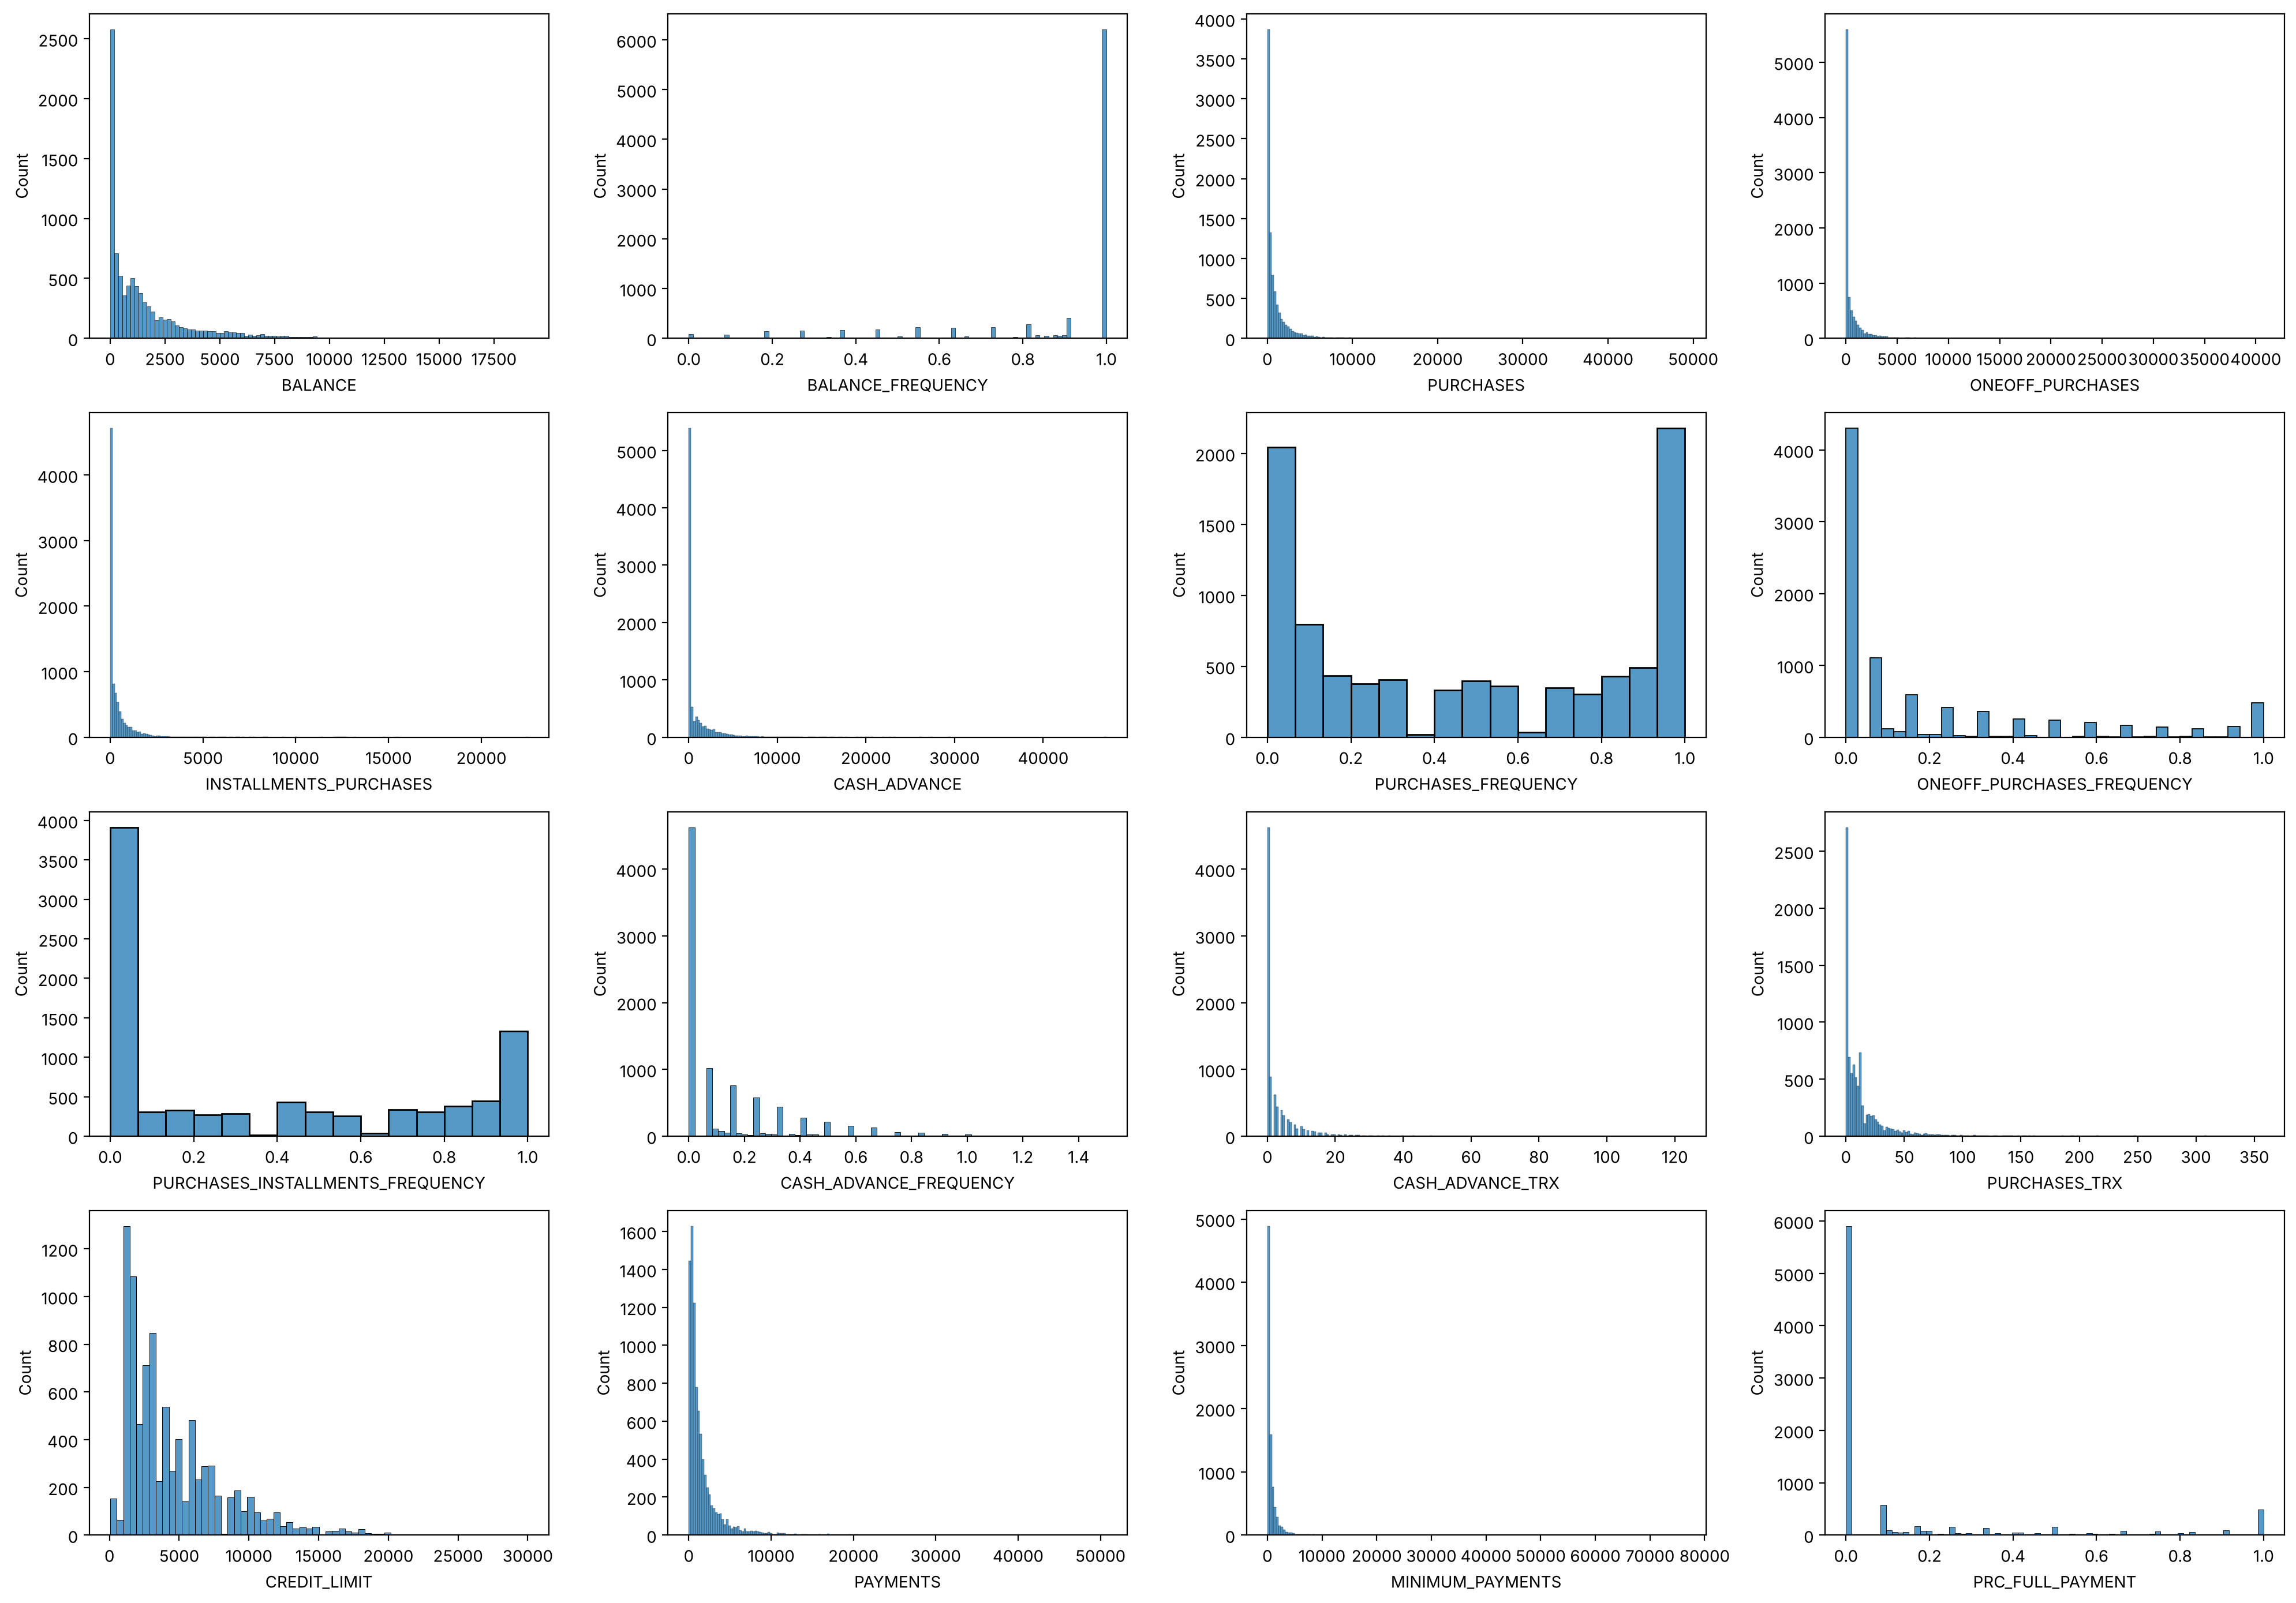

In [8]:
fig, ax = plt.subplots(4, 4, figsize=(20, 14))
for variable, subplot in zip(continuous_features, ax.flatten()):
    sns.histplot(df[variable], ax=subplot)
plt.tight_layout()
plt.show()

**Inferences:**
> * Most amount variables (balance, purchases, cash advance, payments…) are **very right-skewed**: most customers have small amounts, a few have very large ones.
> * Most customers have a tenure of 12 months.

## Step 2) Data cleaning

**Step 2.1) Drop the id and standardise column names** (lowercase, as in the course notebook)

In [9]:
df.drop('CUST_ID', axis=1, inplace=True)
df.columns = df.columns.str.lower()

**Step 2.2) Missing values**

In [10]:
total = df.isnull().sum().sort_values(ascending=False)
percent = (df.isnull().sum() / df.isnull().count() * 100)
missing = pd.concat([total, percent], axis=1, keys=['total', 'percent'])
missing.head()

,total,percent
minimum_payments,313,3.497207
credit_limit,1,0.011173
balance,0,0.000000
balance_frequency,0,0.000000
purchases,0,0.000000


* `minimum_payments`: 313 missing values (3.5%). Dropping them would lose customers, so we **fill them with the median** (the median is not affected by the extreme values).
* `credit_limit`: only 1 missing value, we drop that row.

In [11]:
df['minimum_payments'] = df['minimum_payments'].fillna(df['minimum_payments'].median())
df = df.dropna()
print("we have {} missing values".format(df.isnull().sum().sum()))

we have 0 missing values


**Step 2.3) Inconsistent values**

`cash_advance_frequency` is a frequency, so it should be between 0 and 1. A few rows are above 1, which is impossible: it is a data error. We cap these values at 1.

In [12]:
print("rows with cash_advance_frequency > 1:", (df['cash_advance_frequency'] > 1).sum())
df['cash_advance_frequency'] = df['cash_advance_frequency'].clip(upper=1)

rows with cash_advance_frequency > 1: 8


**Step 2.4) Data manipulation: new features**

As in the course notebook (`total_purchase`, `total_kids`…), we create features that are easier to interpret:
* `credit_utilization` = balance / credit limit: how much of the credit is used.
* `payment_ratio` = payments / minimum payments: does the customer pay more than the minimum?
* `avg_purchase` = purchases / number of purchase transactions: average amount per purchase.

`purchases` is (almost exactly) `oneoff_purchases` + `installments_purchases`. Keeping the three would count the same information twice in the distances used by K-Means, so `purchases` is kept for the analysis (Step 5) but **not used for the clustering**.

In [13]:
df['credit_utilization'] = df['balance'] / df['credit_limit']
df['payment_ratio'] = df['payments'] / df['minimum_payments']
df['avg_purchase'] = np.where(df['purchases_trx'] > 0,
                              df['purchases'] / df['purchases_trx'].replace(0, 1), 0)

# copy with all columns, used later to describe the clusters
df_analysis = df.copy()

df.drop('purchases', axis=1, inplace=True)
df.head()

,balance,balance_frequency,oneoff_purchases,installments_purchases,cash_advance,purchases_frequency,oneoff_purchases_frequency,purchases_installments_frequency,cash_advance_frequency,cash_advance_trx,purchases_trx,credit_limit,payments,minimum_payments,prc_full_payment,tenure,credit_utilization,payment_ratio,avg_purchase
0,40.900749,0.818182,0.00,95.4,0.000000,0.166667,0.000000,0.083333,0.000000,0,2,1000.0,201.802084,139.509787,0.000000,12,0.040901,1.446508,47.700000
1,3202.467416,0.909091,0.00,0.0,6442.945483,0.000000,0.000000,0.000000,0.250000,4,0,7000.0,4103.032597,1072.340217,0.222222,12,0.457495,3.826241,0.000000
2,2495.148862,1.000000,773.17,0.0,0.000000,1.000000,1.000000,0.000000,0.000000,0,12,7500.0,622.066742,627.284787,0.000000,12,0.332687,0.991682,64.430833
3,1666.670542,0.636364,1499.00,0.0,205.788017,0.083333,0.083333,0.000000,0.083333,1,1,7500.0,0.000000,312.343947,0.000000,12,0.222223,0.000000,1499.000000
4,817.714335,1.000000,16.00,0.0,0.000000,0.083333,0.083333,0.000000,0.000000,0,1,1200.0,678.334763,244.791237,0.000000,12,0.681429,2.771075,16.000000


**Step 2.5) Extreme values**

The course notebook removed the outliers (age > 90, income > 600000). Here, the extreme values are not errors: they are **big spenders**, which are an interesting segment for the company. Removing them would also remove a large part of the customers.

Instead, we apply a **log transformation** (`log1p` = log(1 + x), which works with zeros) to the amount variables. It reduces the skewness so that a few very large values do not dominate the clustering.

`USE_LOG = False` reruns the notebook without it (to compare: without log, K-Means creates tiny clusters of a few extreme customers).

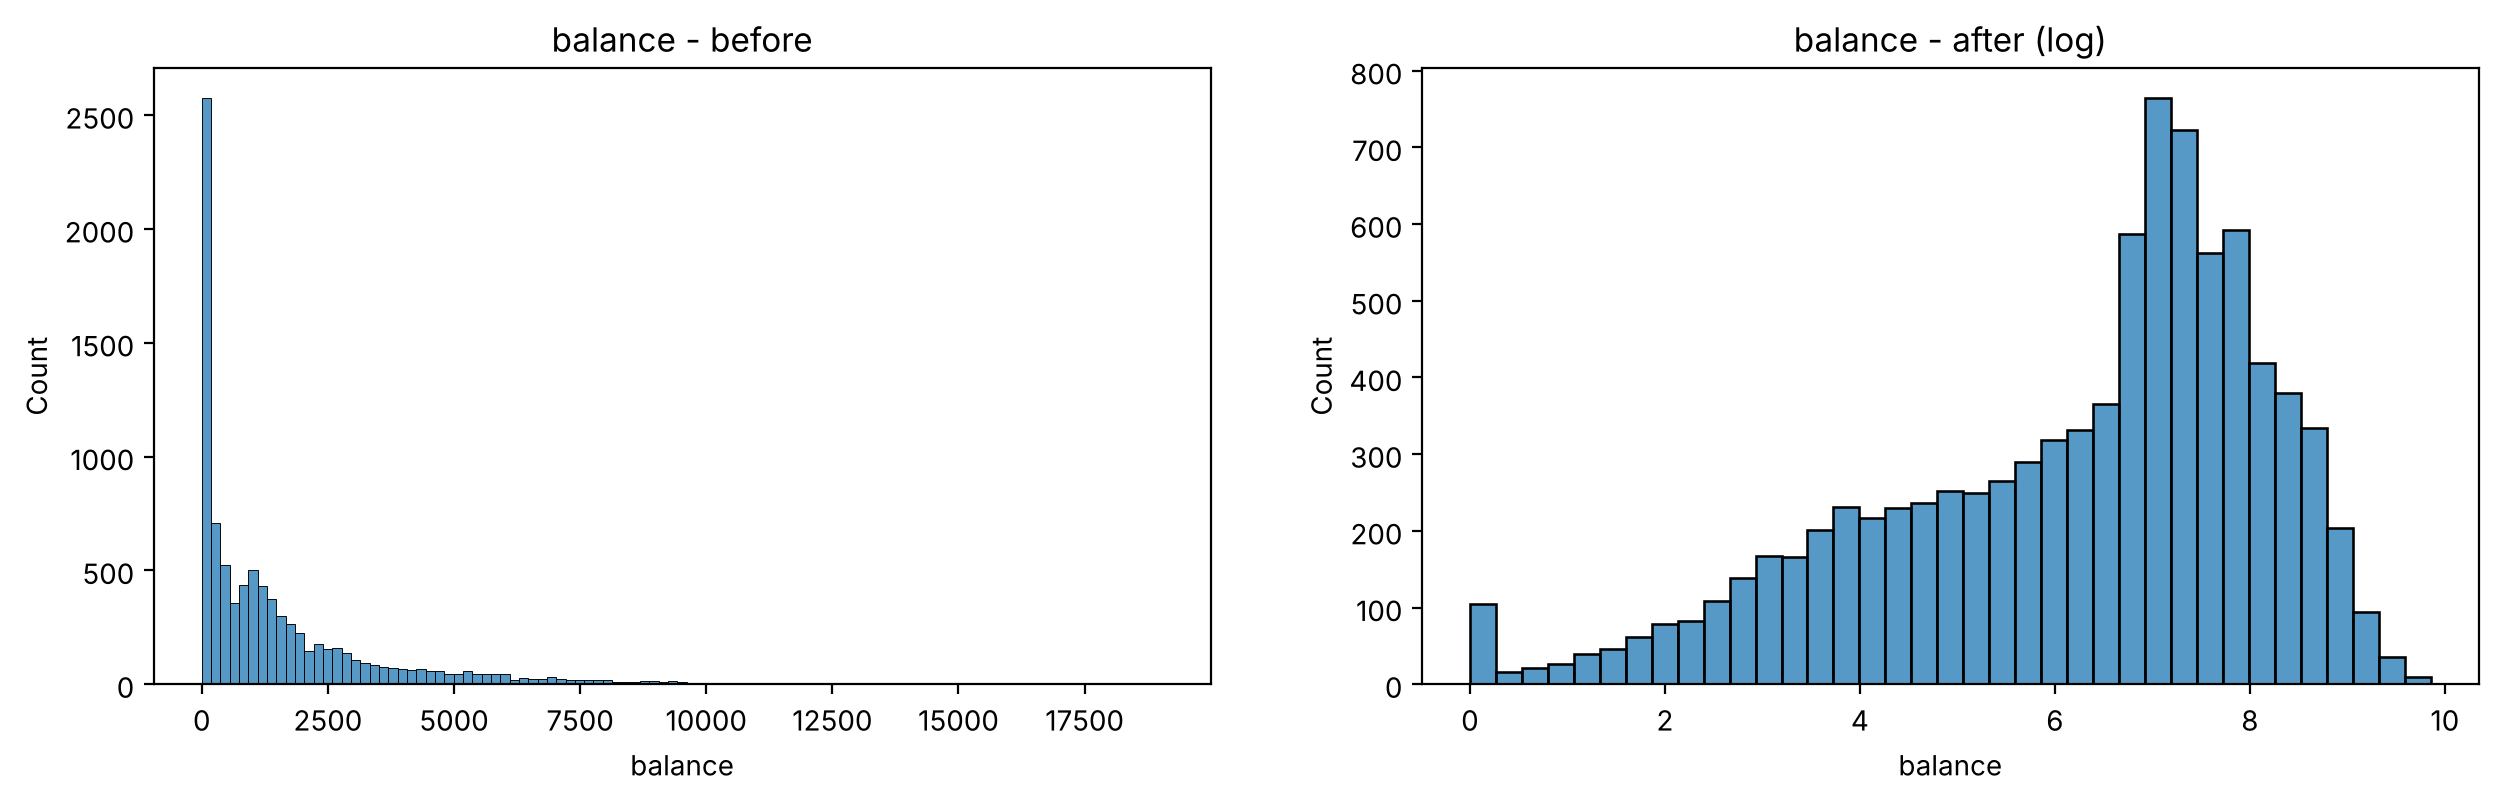

In [14]:
USE_LOG = True

amount_features = ['balance', 'oneoff_purchases', 'installments_purchases', 'cash_advance',
                   'cash_advance_trx', 'purchases_trx', 'credit_limit', 'payments',
                   'minimum_payments', 'credit_utilization', 'payment_ratio', 'avg_purchase']

df_model = df.copy()
if USE_LOG:
    df_model[amount_features] = np.log1p(df_model[amount_features])

fig, ax = plt.subplots(1, 2, figsize=(15, 4))
sns.histplot(df['balance'], ax=ax[0]).set_title('balance - before')
sns.histplot(df_model['balance'], ax=ax[1]).set_title('balance - after (log)' if USE_LOG else 'balance')
plt.show()

**Step 2.6) Correlation**

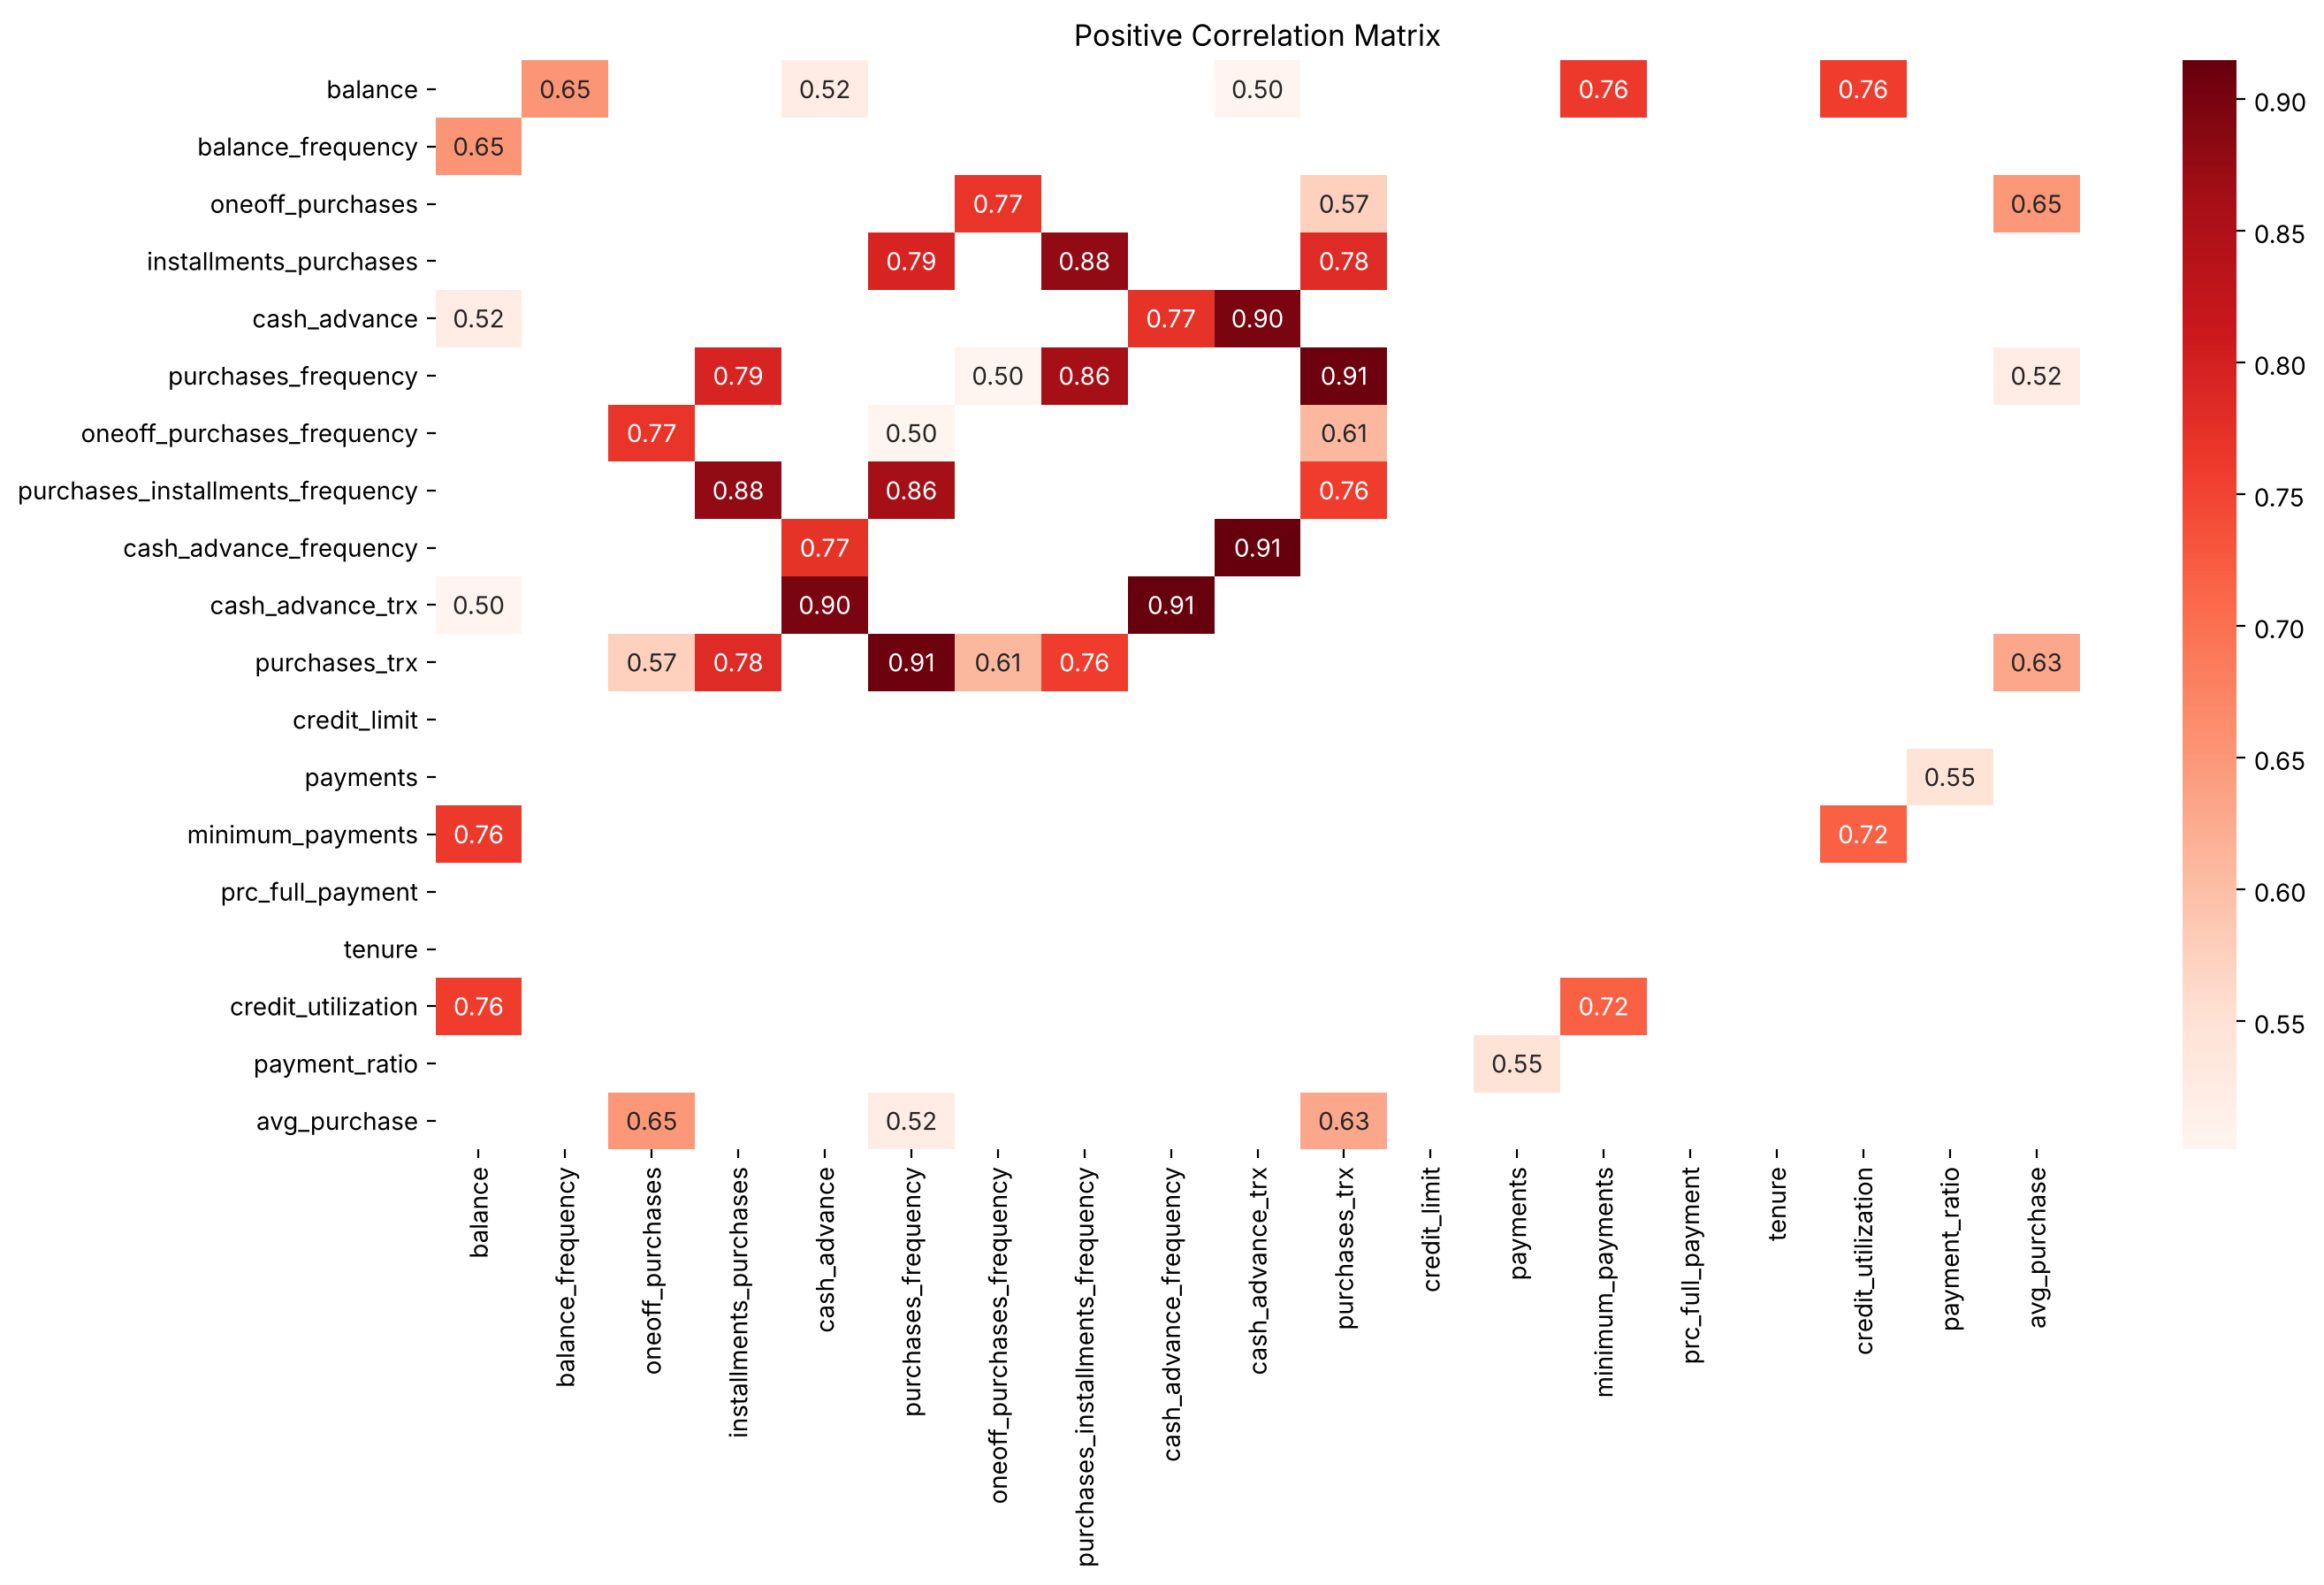

In [15]:
pos_corrmat = df_model.corr(numeric_only=True)

# Filter for values >= 0.5 and excluding 1.0 (self-correlation)
filtereddf = pos_corrmat[(pos_corrmat >= 0.5) & (pos_corrmat != 1.000)]

plt.figure(figsize=(15, 8))
sns.heatmap(filtereddf, annot=True, fmt='.2f', cmap="Reds")
plt.title('Positive Correlation Matrix')
plt.show()

## Step 3) Data preparation

**Why standardize?** The variables have very different scales (frequencies between 0 and 1, amounts in thousands). K-Means uses distances, so without scaling the large amounts would dominate.

No one-hot encoding is needed: all variables are numerical.

In [16]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
df2 = scaler.fit_transform(df_model)
df2 = pd.DataFrame(df2, columns=df_model.columns)
df2.head()

,balance,balance_frequency,oneoff_purchases,installments_purchases,cash_advance,purchases_frequency,oneoff_purchases_frequency,purchases_installments_frequency,cash_advance_frequency,cash_advance_trx,purchases_trx,credit_limit,payments,minimum_payments,prc_full_payment,tenure,credit_utilization,payment_ratio,avg_purchase
0,-1.205498,-0.249881,-0.987198,0.394362,-0.930636,-0.806649,-0.678716,-0.707409,-0.677360,-0.810038,-0.579693,-1.447095,-0.825080,-0.830442,-0.525588,0.360541,-1.022945,-0.492536,0.390960
1,0.948821,0.134049,-0.987198,-1.087586,1.528788,-1.221928,-0.678716,-0.917090,0.577304,0.784546,-1.379434,0.925997,1.065109,0.908205,0.234159,0.360541,0.322058,0.230156,-1.672337
2,0.824885,0.517980,1.061910,-1.087586,-0.930636,1.269742,2.673295,-0.917090,-0.677360,-0.810038,0.487735,1.010161,-0.119646,0.450264,-0.525588,0.360541,-0.035625,-0.711323,0.547772
3,0.624529,-1.017743,1.265665,-1.087586,0.564410,-1.014290,-0.399383,-0.917090,-0.259140,-0.123288,-0.874853,1.010161,-4.163779,-0.144626,-0.525588,0.360541,-0.381335,-1.444199,2.210986
4,0.271106,0.517980,-0.114417,-1.087586,-0.930636,-1.014290,-0.399383,-0.917090,-0.677360,-0.810038,-0.874853,-1.224854,-0.065306,-0.352262,-0.525588,0.360541,0.893107,-0.032270,-0.167900


In [17]:
scaled_df = df2.copy()

## Step 4) Modelling

### K-Means clustering
* Randomly select k points (centroids)
* Assign each customer to its nearest centroid
* Recompute the centroids and repeat until they no longer move

We test several values of k (2 to 10) with two methods, then choose one.

**Step 4.1) Elbow method** (distortion = sum of squared distances to the centroid)

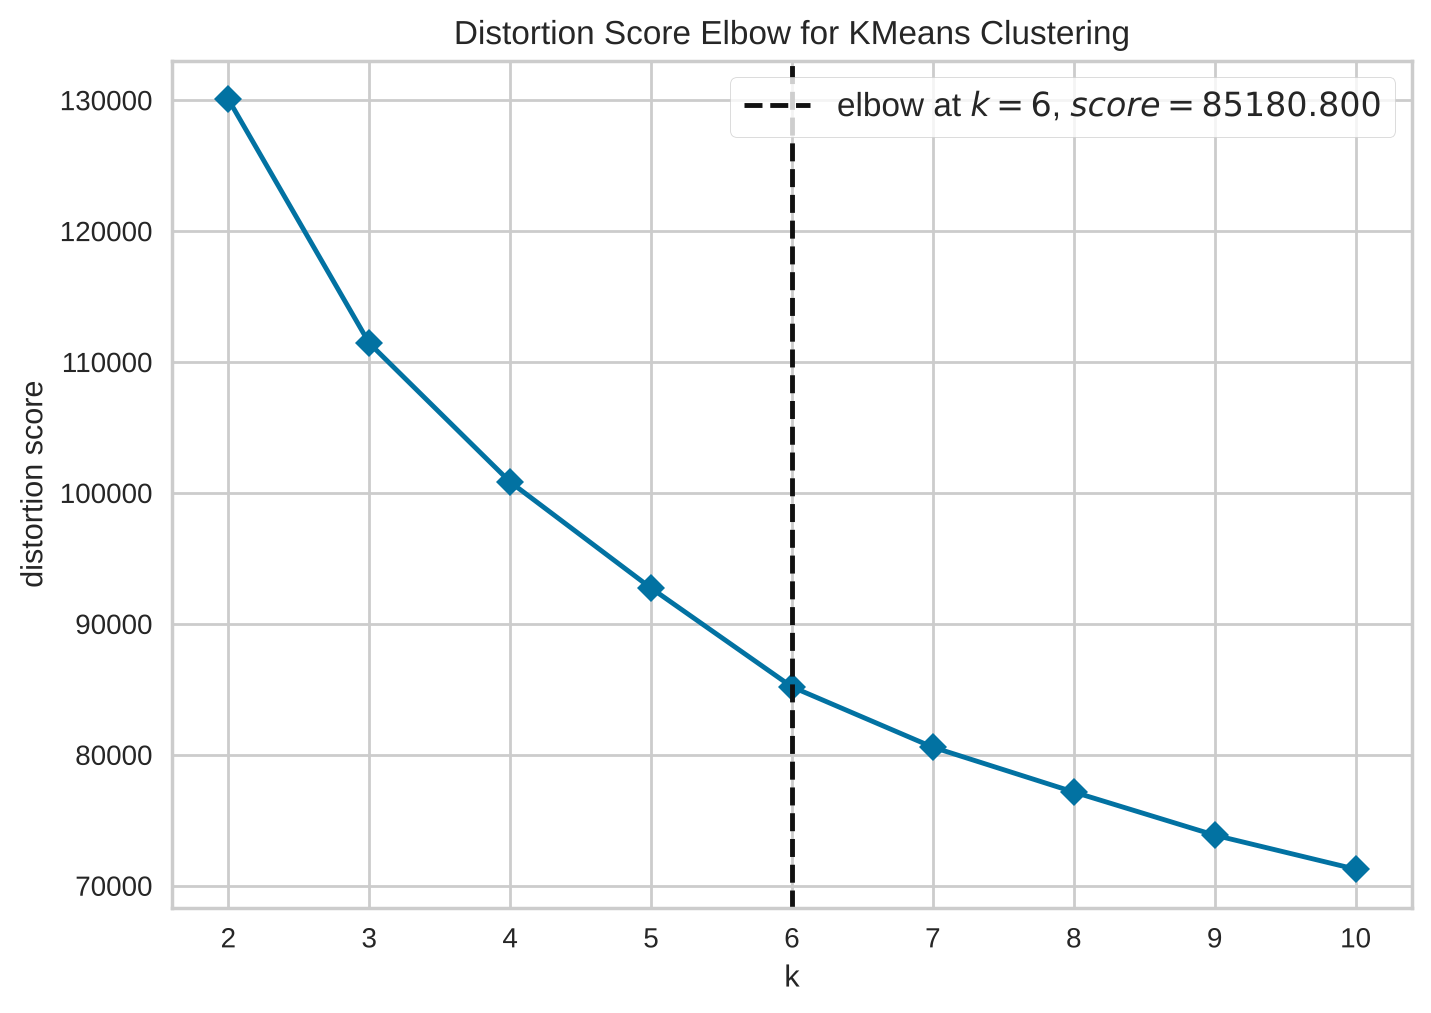

In [18]:
from sklearn.cluster import KMeans
from yellowbrick.cluster import KElbowVisualizer
model = KMeans(random_state=42, n_init=10)
visualizer = KElbowVisualizer(model, k=(2, 11), timings=False)
visualizer.fit(scaled_df)
visualizer.show();

**Step 4.2) Silhouette score** (between -1 and 1: how well each customer fits its cluster compared to the closest other cluster; higher is better)

In [19]:
from sklearn.metrics import silhouette_score

results = []
for k in range(2, 11):
    km = KMeans(n_clusters=k, init='k-means++', random_state=42, n_init=10)
    labels = km.fit_predict(scaled_df)
    results.append({'k': k,
                    'distortion': km.inertia_,
                    'silhouette': silhouette_score(scaled_df, labels, sample_size=4000, random_state=0),
                    'smallest cluster': np.bincount(labels).min()})
pd.DataFrame(results).round(3)

,k,distortion,silhouette,smallest cluster
0,2,130065.211,0.231,3618
1,3,111434.418,0.209,2709
2,4,100832.409,0.188,1809
3,5,92724.737,0.189,1353
4,6,85180.881,0.202,1127
5,7,80573.175,0.200,991
6,8,77150.036,0.199,697
7,9,73855.164,0.203,390
8,10,71255.992,0.172,230


**Choice of k**
* The elbow method suggests **k = 6**.
* The silhouette score is low for all k (around 0.2): the customers form a continuum rather than clearly separated groups, which is common with behavioural data. It is highest for small k.
* **k = 4** is a compromise: the distortion has already dropped a lot, all clusters are large enough, and the 4 segments are clearly different and easy to turn into marketing actions (Step 5).

`K` can be changed below to compare (e.g. `K = 6`).

In [20]:
K = 4

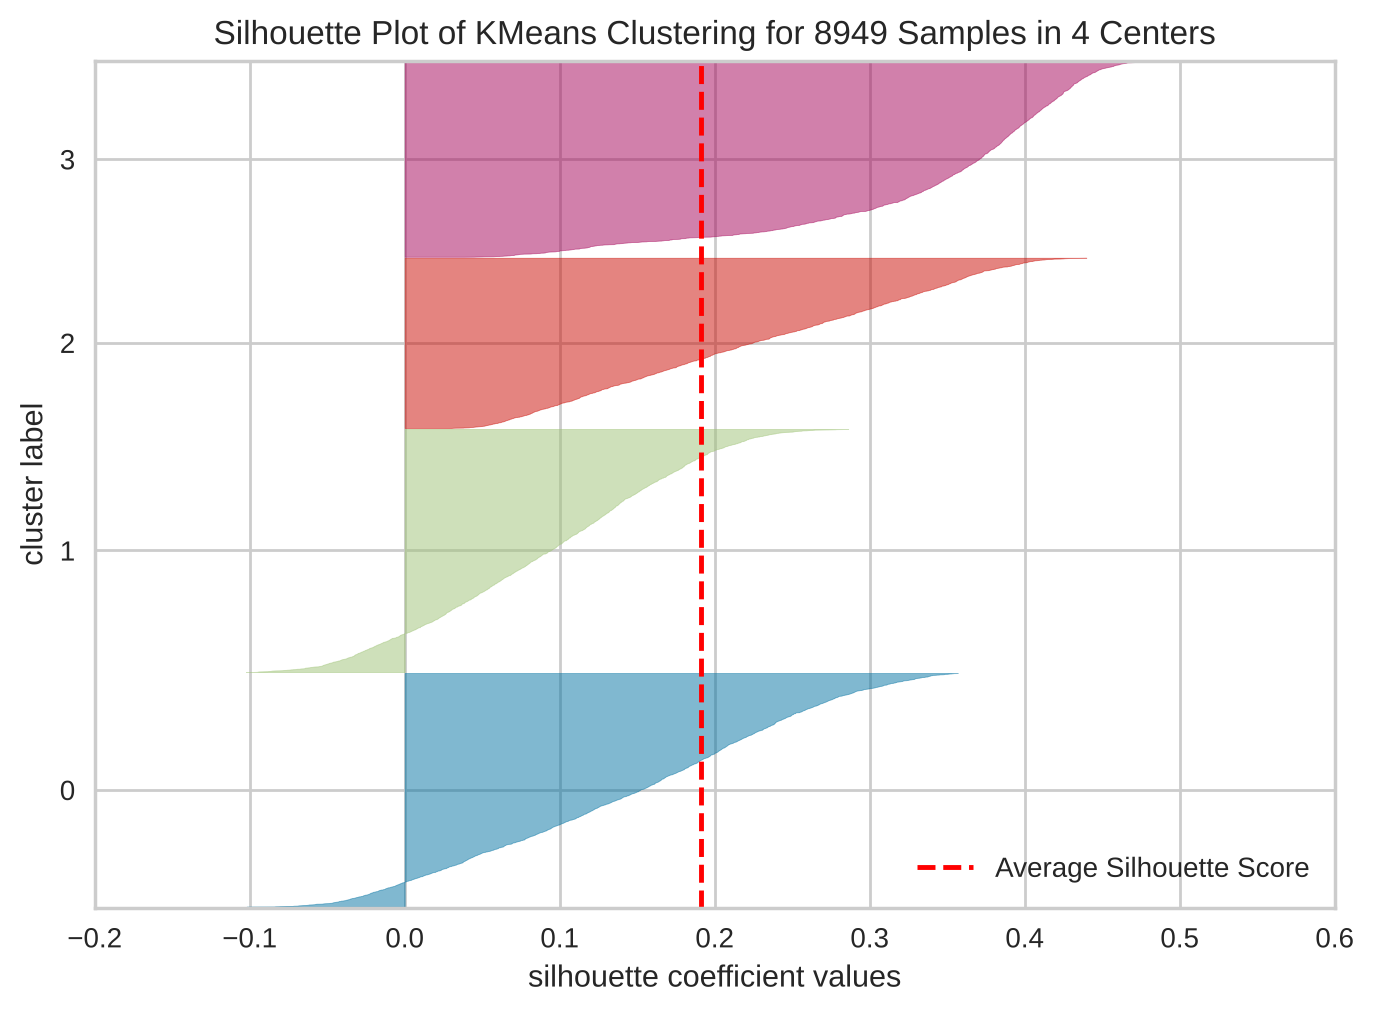

In [21]:
from yellowbrick.cluster import SilhouetteVisualizer
sil_visualizer = SilhouetteVisualizer(KMeans(n_clusters=K, random_state=42, n_init=10), colors='yellowbrick')
sil_visualizer.fit(scaled_df)
sil_visualizer.show();

**Step 4.3) Train the model**

In [22]:
kmeans = KMeans(n_clusters=K, init='k-means++', random_state=42, n_init=10)
pred_kmeans = kmeans.fit_predict(scaled_df)

Let us add the predicted cluster to the original data (+1 so that clusters start at 1).

In [23]:
df_analysis['cluster'] = pred_kmeans + 1
df_analysis['cluster'].value_counts().sort_index()

cluster
1    2484
2    2583
3    1809
4    2073
Name: count, dtype: int64

## Step 5) Cluster analysis

**Step 5.1) Descriptive statistics per cluster** (median, less sensitive to extreme values than the mean)

In [24]:
profile_cols = ['balance', 'purchases', 'oneoff_purchases', 'installments_purchases', 'cash_advance',
                'purchases_frequency', 'cash_advance_frequency', 'credit_limit', 'credit_utilization',
                'payments', 'prc_full_payment', 'tenure']

summary = df_analysis.groupby('cluster')[profile_cols].median().T
summary.loc['size'] = df_analysis['cluster'].value_counts().sort_index()
summary.loc['share (%)'] = (df_analysis['cluster'].value_counts(normalize=True).sort_index() * 100)
summary.round(2)

cluster,1,2,3,4
balance,42.29,1728.95,594.27,1522.68
purchases,307.20,518.31,2084.64,0.00
oneoff_purchases,0.00,204.00,1201.42,0.00
installments_purchases,178.90,135.27,628.72,0.00
cash_advance,0.00,526.95,0.00,1340.13
purchases_frequency,0.50,0.50,1.00,0.00
cash_advance_frequency,0.00,0.17,0.00,0.25
credit_limit,2500.00,3000.00,6000.00,3000.00
credit_utilization,0.02,0.71,0.13,0.63
payments,386.61,1010.44,1934.82,780.19


In [25]:
df_analysis.groupby('cluster')[profile_cols].mean().T.round(2)

cluster,1,2,3,4
balance,106.06,2595.38,1320.20,2241.42
purchases,441.93,904.48,3061.17,3.37
oneoff_purchases,140.37,509.14,2008.14,2.80
installments_purchases,302.00,395.66,1053.40,0.63
cash_advance,50.14,1539.33,173.22,2096.82
purchases_frequency,0.54,0.55,0.89,0.01
cash_advance_frequency,0.01,0.21,0.03,0.29
credit_limit,3395.64,4330.02,6684.60,4104.76
credit_utilization,0.05,0.67,0.21,0.60
payments,698.54,1837.74,3034.81,1707.48


**Step 5.2) Plots per cluster**

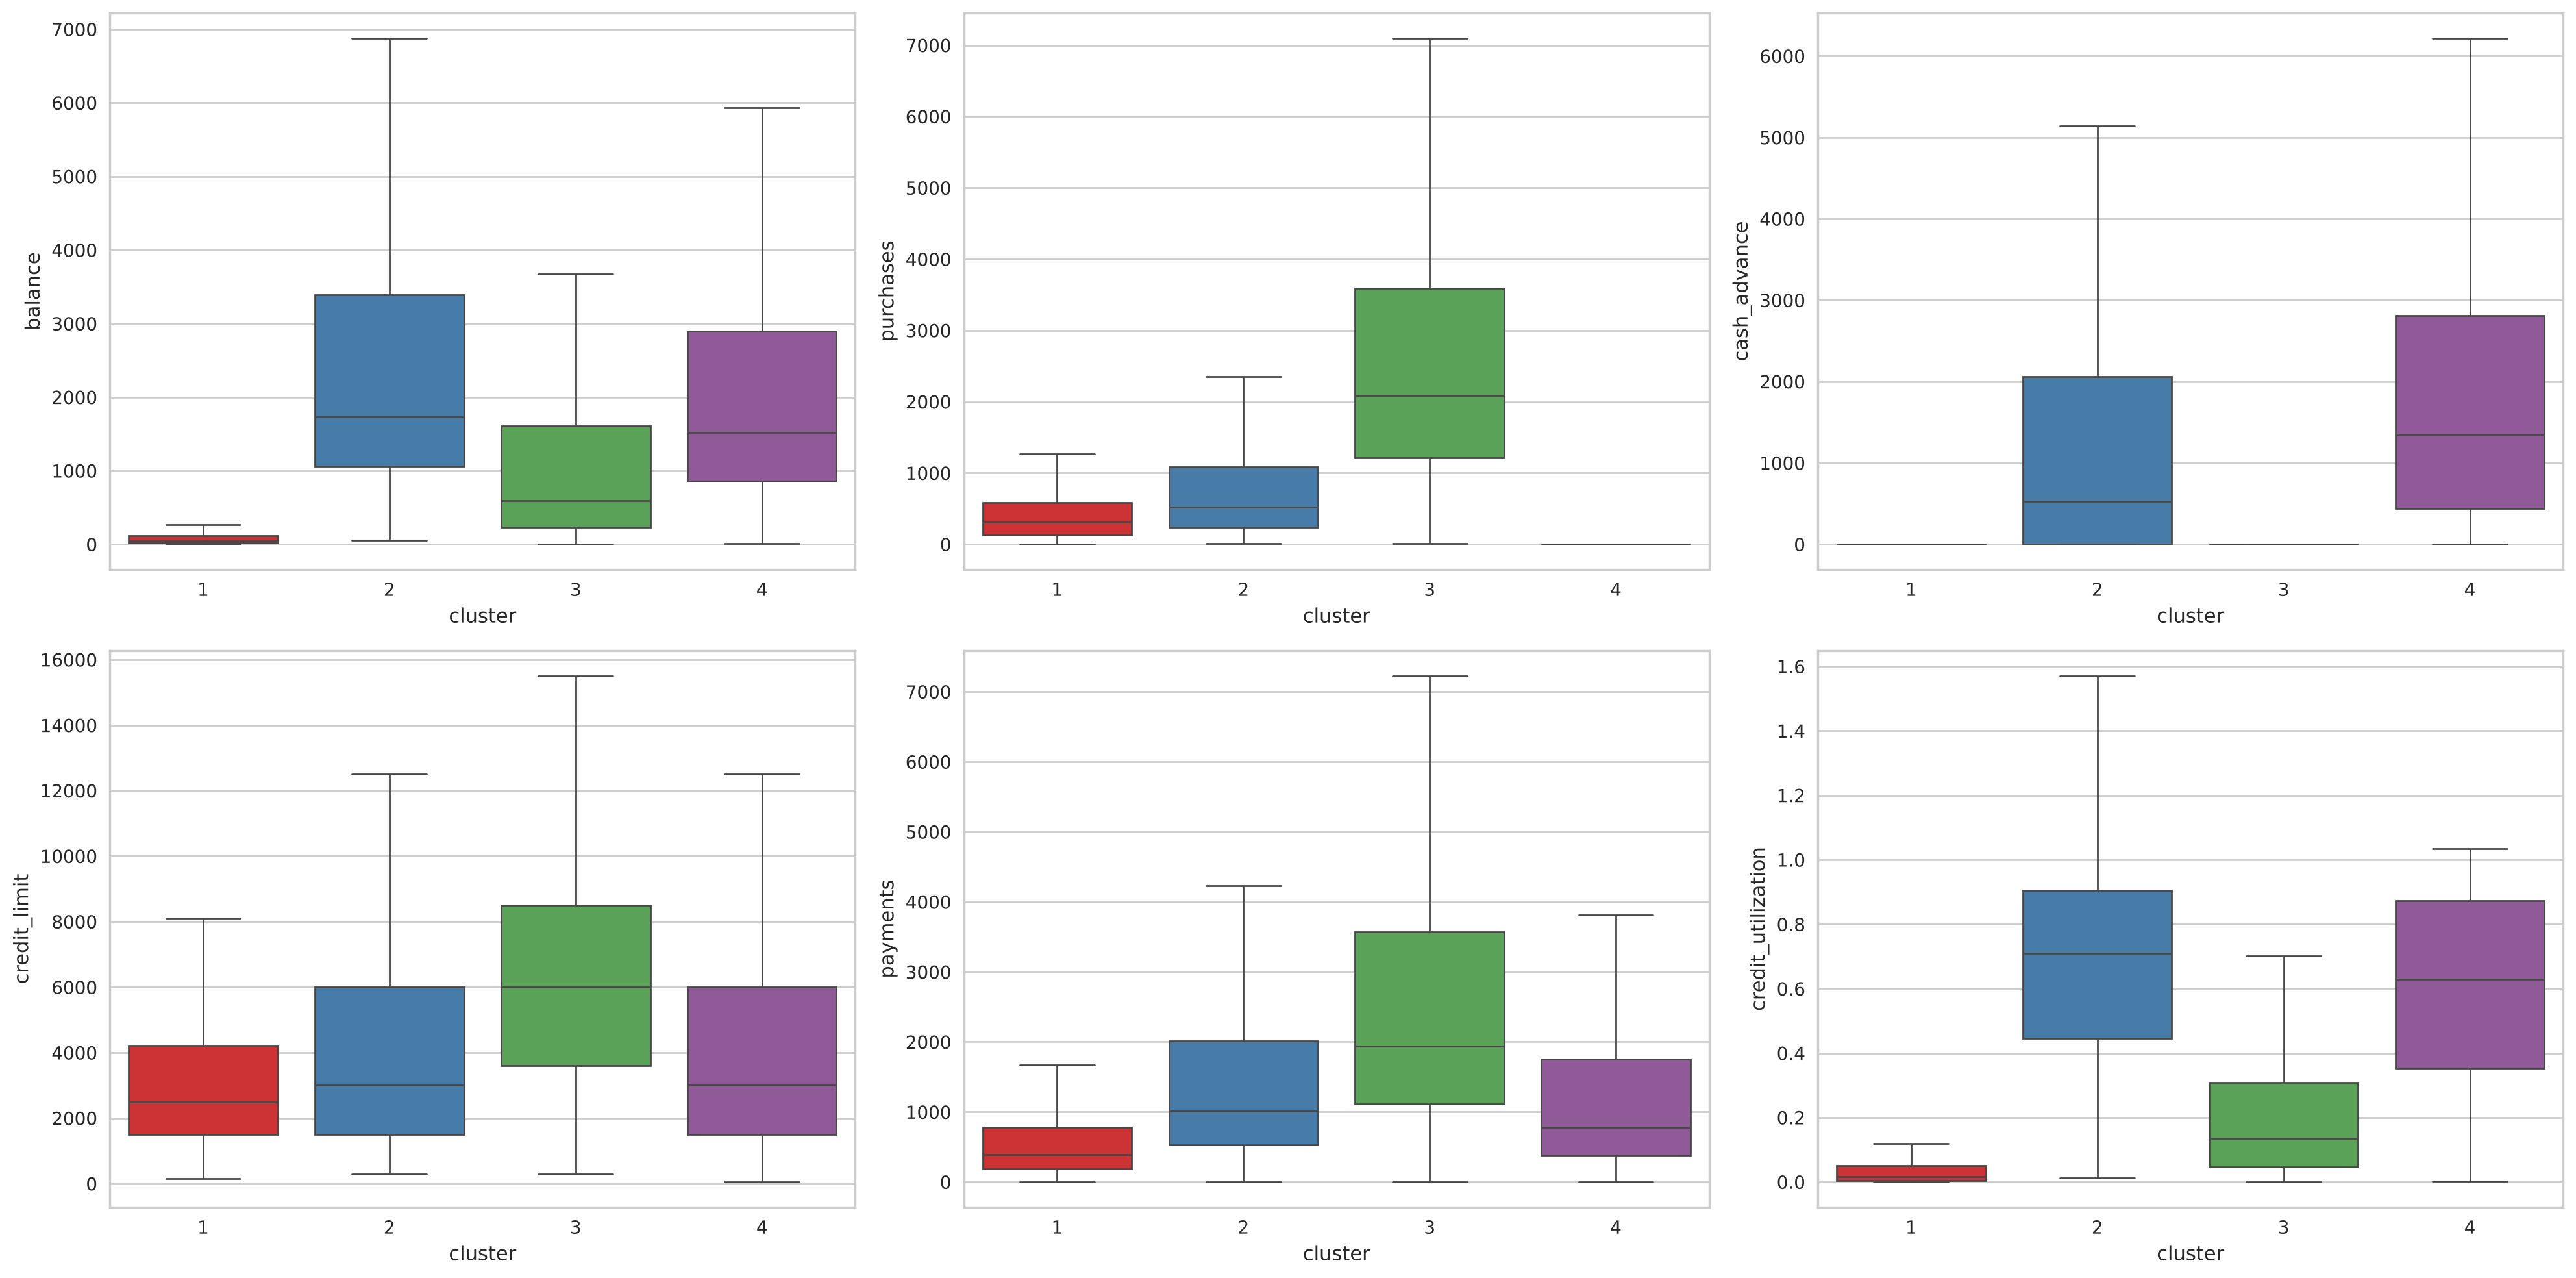

In [26]:
key_features = ['balance', 'purchases', 'cash_advance', 'credit_limit', 'payments', 'credit_utilization']

fig, ax = plt.subplots(2, 3, figsize=(20, 10))
sns.set_style('darkgrid')
for variable, subplot in zip(key_features, ax.flatten()):
    sns.boxplot(data=df_analysis, x='cluster', y=variable, ax=subplot, palette='Set1', showfliers=False)
plt.tight_layout()
plt.show()

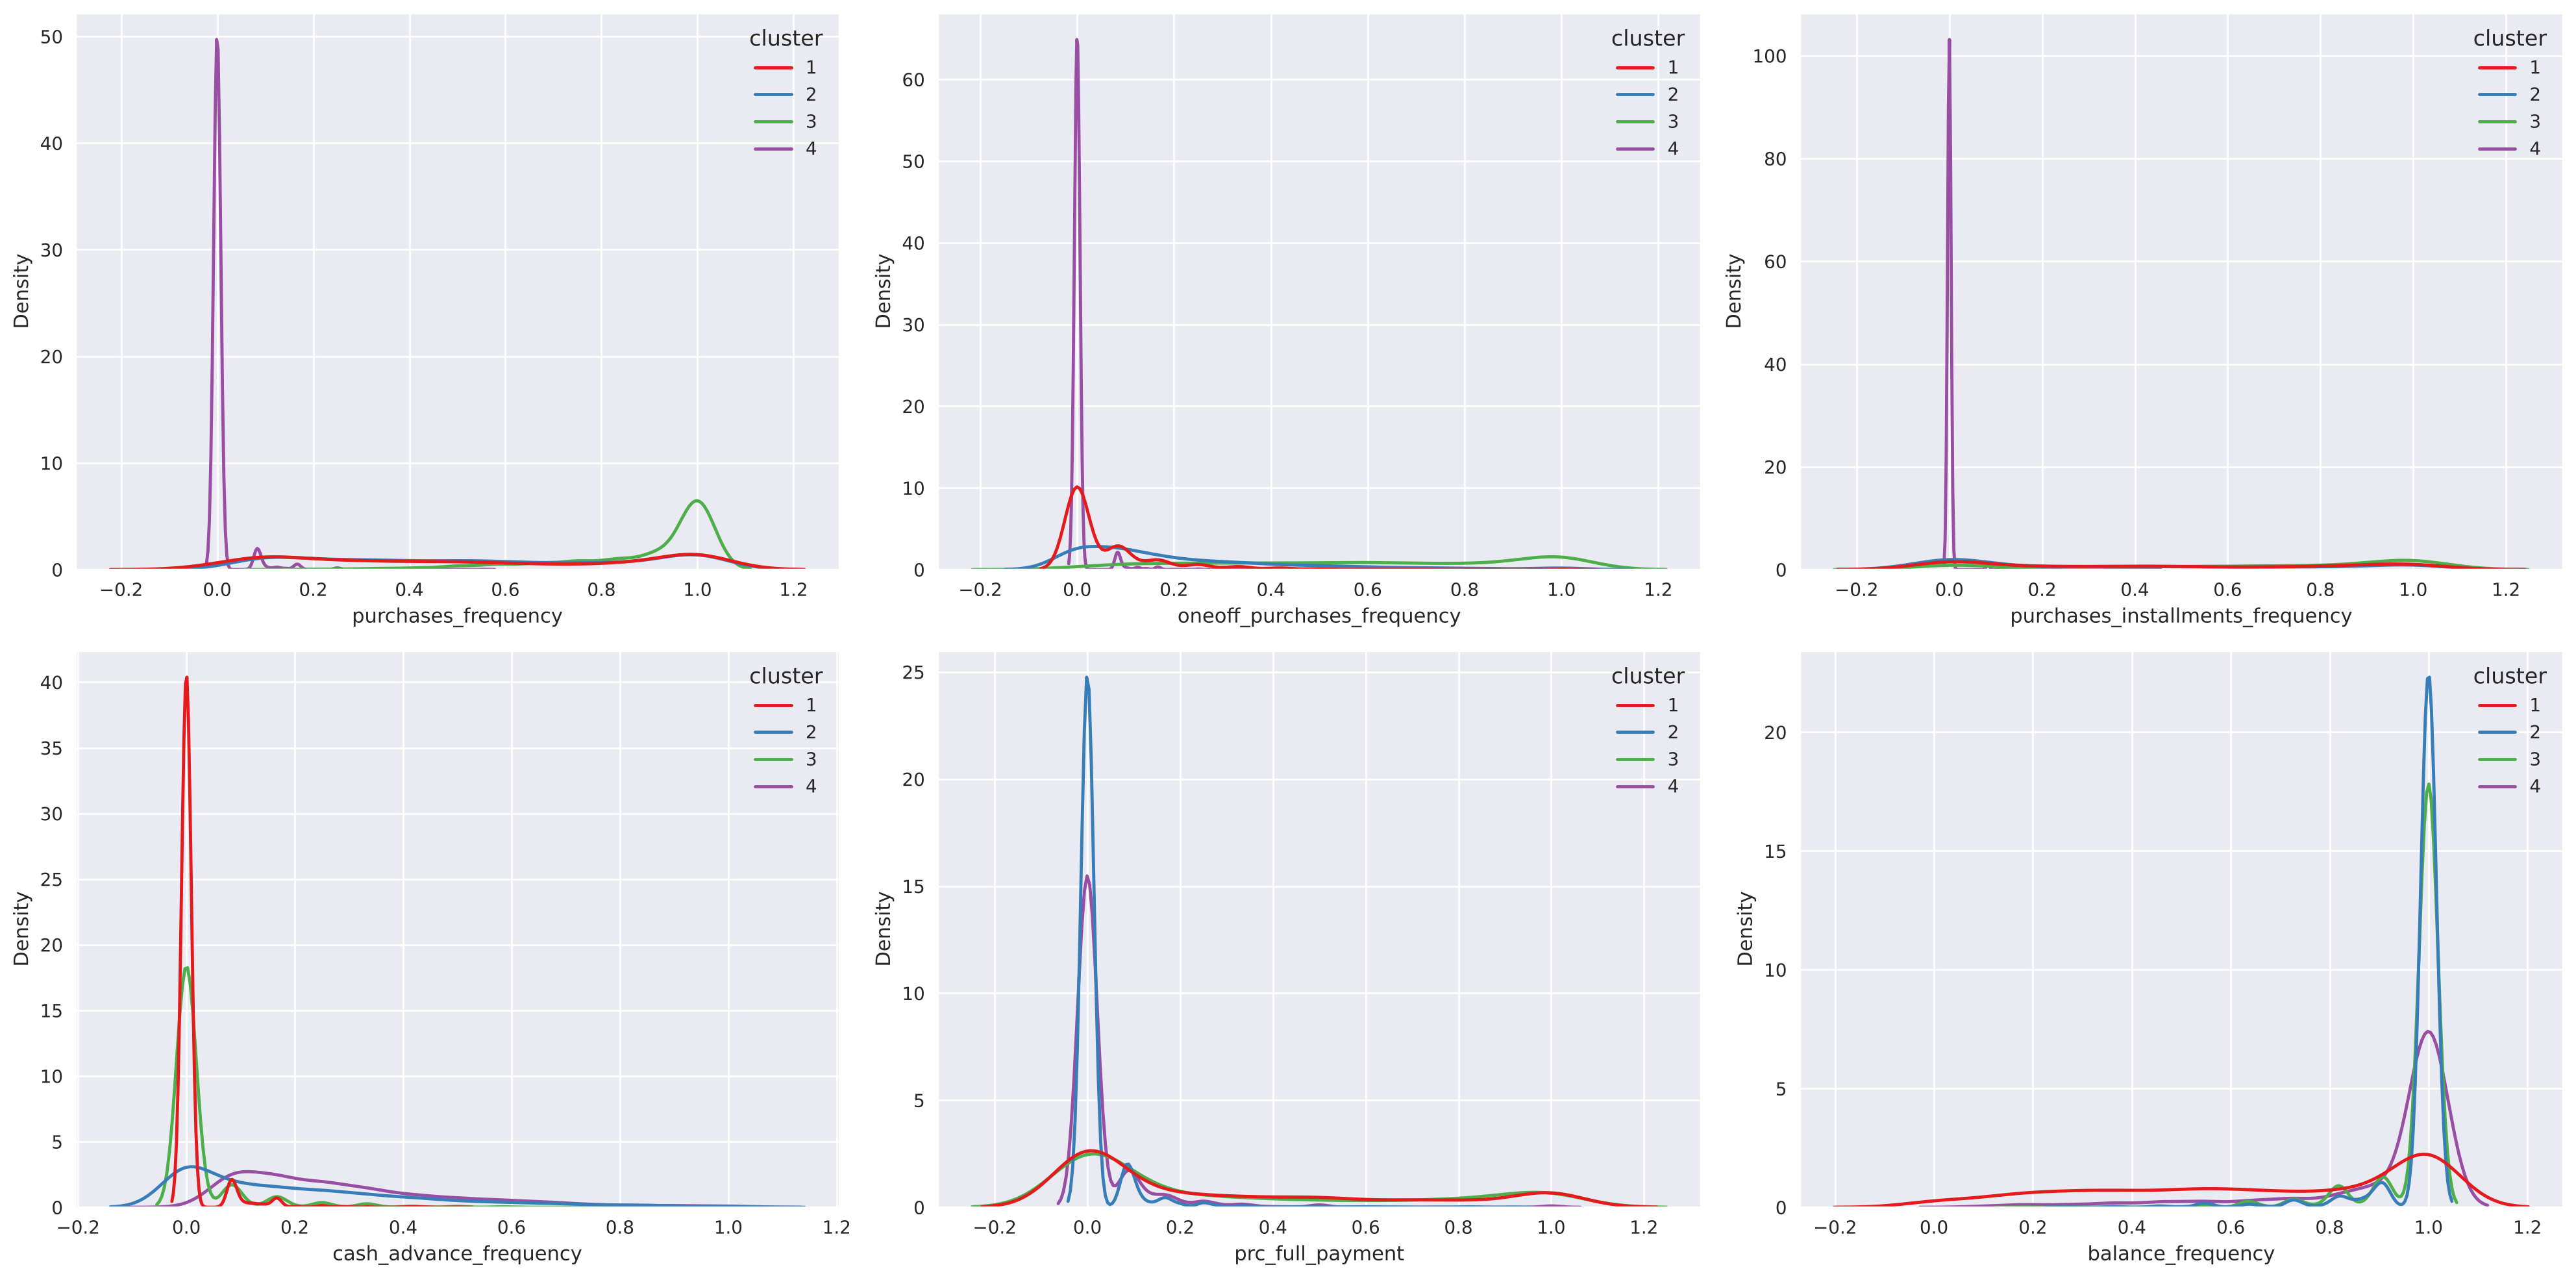

In [27]:
freq_features = ['purchases_frequency', 'oneoff_purchases_frequency', 'purchases_installments_frequency',
                 'cash_advance_frequency', 'prc_full_payment', 'balance_frequency']

fig, ax = plt.subplots(2, 3, figsize=(20, 10))
for variable, subplot in zip(freq_features, ax.flatten()):
    sns.kdeplot(data=df_analysis, x=variable, hue='cluster', ax=subplot, palette='Set1', common_norm=False)
plt.tight_layout()
plt.show()

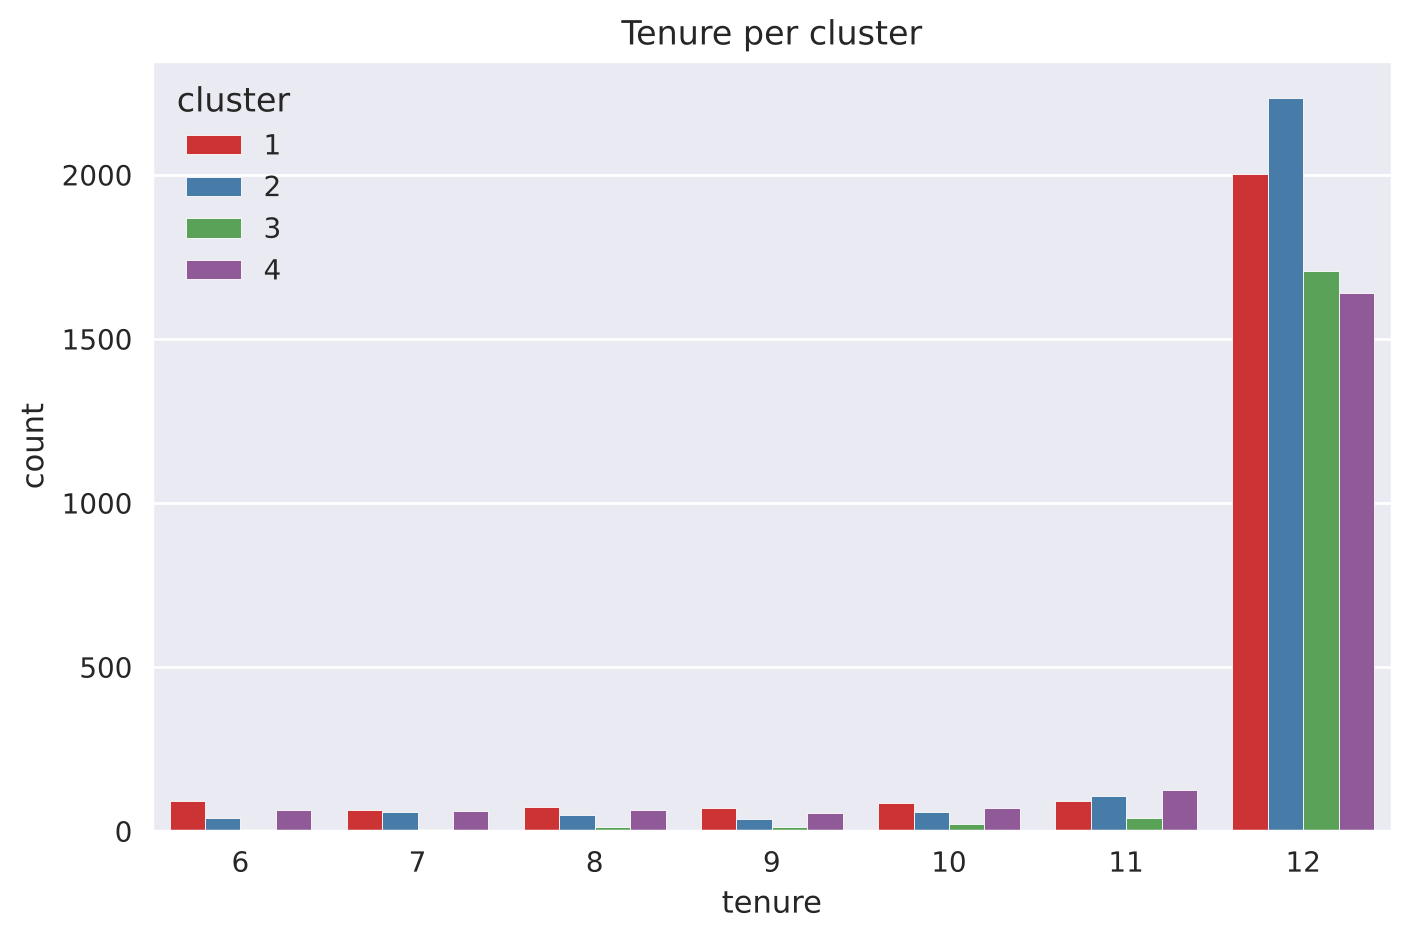

In [28]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df_analysis, x='tenure', hue='cluster', palette='Set1')
plt.title('Tenure per cluster')
plt.show()

**Step 5.3) 2D view of the clusters (PCA)**: projects the variables on 2 axes, only to visualise the clusters.

variance explained by the 2 axes: 52%


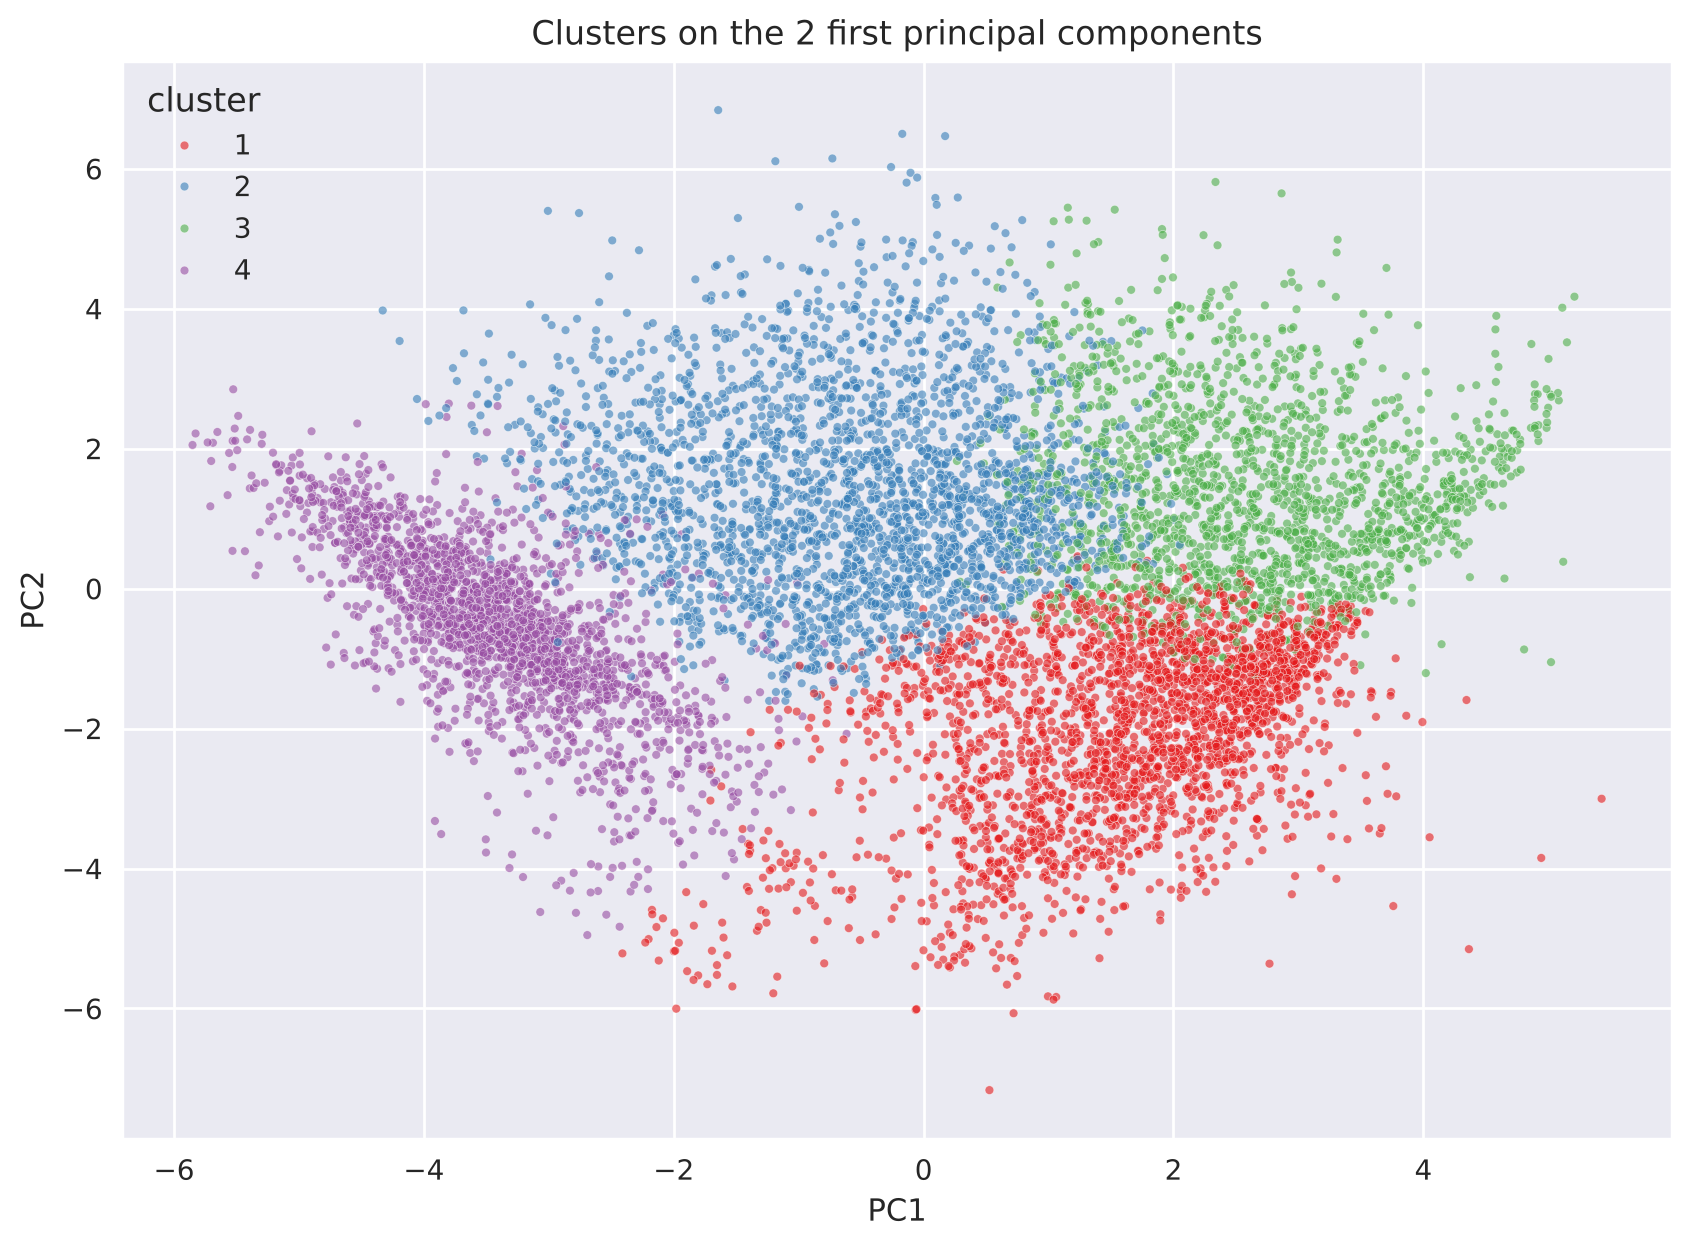

In [29]:
from sklearn.decomposition import PCA
pca = PCA(n_components=2, random_state=42)
coords = pca.fit_transform(scaled_df)
print("variance explained by the 2 axes: {:.0%}".format(pca.explained_variance_ratio_.sum()))

plt.figure(figsize=(10, 7))
sns.scatterplot(x=coords[:, 0], y=coords[:, 1], hue=df_analysis['cluster'], palette='Set1', s=10, alpha=0.6)
plt.xlabel('PC1'); plt.ylabel('PC2'); plt.title('Clusters on the 2 first principal components')
plt.show()

**Step 5.4) Cluster profiles**

The cluster numbers depend on the run, so the names are assigned from the statistics:
* **Cash advance users**: almost no purchases, use their card to withdraw cash.
* **Big spenders**: highest purchases, buy very often, highest credit limit.
* **Low-balance careful users**: lowest balance, moderate purchases, no cash advance.
* **Revolvers**: high credit utilization, mix purchases and cash advance, rarely pay in full.

In [30]:
med = df_analysis.groupby('cluster')[profile_cols].median()
names = {}
names[med['purchases'].idxmin()] = 'Cash advance users'
names[med.drop(index=list(names))['purchases'].idxmax()] = 'Big spenders'
names[med.drop(index=list(names))['balance'].idxmin()] = 'Low-balance careful users'
for c in med.index:
    names.setdefault(c, 'Revolvers')

df_analysis['profile'] = df_analysis['cluster'].map(names)
summary.columns = [f"{c} - {names[c]}" for c in summary.columns]
summary.round(2)

,1 - Low-balance careful users,2 - Revolvers,3 - Big spenders,4 - Cash advance users
balance,42.29,1728.95,594.27,1522.68
purchases,307.20,518.31,2084.64,0.00
oneoff_purchases,0.00,204.00,1201.42,0.00
installments_purchases,178.90,135.27,628.72,0.00
cash_advance,0.00,526.95,0.00,1340.13
purchases_frequency,0.50,0.50,1.00,0.00
cash_advance_frequency,0.00,0.17,0.00,0.25
credit_limit,2500.00,3000.00,6000.00,3000.00
credit_utilization,0.02,0.71,0.13,0.63
payments,386.61,1010.44,1934.82,780.19


## Step 6) Marketing actions

| Profile | What we see | Marketing actions |
|---|---|---|
| **Big spenders** | Buy very often, large one-off and installment purchases, high credit limit, no cash advance | Premium card / rewards programme (cashback, travel miles); partnerships with retailers; offer a credit limit increase to keep them |
| **Revolvers** | High credit utilization, purchases + cash advance, rarely pay in full | Balance transfer or installment plans at a lower rate; alerts before reaching the limit; monitor the credit risk closely |
| **Cash advance users** | Almost no purchases, regular cash withdrawals, high utilization | Encourage card purchases instead of cash (purchase bonus, merchant offers); review cash advance fees and limits; treat as higher risk |
| **Low-balance careful users** | Low balance, small purchases (often installments), no cash advance | Activation campaigns (first-purchase bonus, installment offers at partners); cross-sell other products; low-cost segment to grow |

*To check against the statistics of Step 5 if `K` or the cleaning choices are changed.*

## Conclusion

* After cleaning (median imputation, capping an inconsistent frequency, log transformation of the amounts) and scaling, K-Means splits the customers into **4 segments** based on how they use their card.
* The segments differ mainly on **purchases vs cash advance** and on **how much of the credit is used and repaid**.
* Each segment calls for a different strategy: retain and reward the big spenders, manage the risk of revolvers and cash advance users, and activate the low-balance customers.
* Limits: no demographic data, low silhouette scores (segments overlap), and K-Means assumes round clusters of similar size.